In [10]:
#import warnings
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
#from itertools import product
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import seaborn as sns
import warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)


import sys
sys.path.append(str(Path("../src").resolve())) 
from utils import clean



In [11]:
X_train = pd.read_csv("../data/model_data/xtrain_final.csv").drop(columns="Unnamed: 0")
y_train = pd.read_csv("../data/model_data/ytrain_final.csv").drop(columns="Unnamed: 0")

X_val = pd.read_csv("../data/model_data/xval_final.csv").drop(columns="Unnamed: 0")
y_val = pd.read_csv("../data/model_data/yval_final.csv").drop(columns="Unnamed: 0")

X_test = pd.read_csv("../data/model_data/xtest_final.csv").drop(columns="Unnamed: 0")
y_test = pd.read_csv("../data/model_data/ytest_final.csv").drop(columns="Unnamed: 0")

In [12]:
X_train = X_train.fillna(0)
X_val = X_val.fillna(0)
X_test = X_test.fillna(0)

In [13]:
non_numeric = X_train.select_dtypes(exclude='number').columns.to_list()
non_numeric


['player',
 'position',
 'next_week_opponent',
 'next_week_atVs',
 'next_week_roof',
 'next_week_surface',
 'next_week_location']

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Fit the encoder on the training set only, then reuse it for val/test so every
# split gets exactly the same columns. Categories not seen in training
# (e.g. new players) are encoded as all zeros instead of raising an error.
encoder = ColumnTransformer(
    [("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=int), non_numeric)],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

# fillna(0) left int 0s in some string columns (surface/location); the encoder
# needs a single type per column, so cast categoricals to str.
for df in (X_train, X_val, X_test):
    df[non_numeric] = df[non_numeric].astype(str)

encoded_train = encoder.fit_transform(X_train)
encoded_val = encoder.transform(X_val)
encoded_test = encoder.transform(X_test)

In [15]:

model = LinearRegression()
model.fit(encoded_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 949)","[[16.07, 1.46,-4.42,..., 0.11, 0.06, 0.34]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](949,)","['player_A.J. Brown','player_AJ Barner','player_AJ Dillon',..., 'receivingTargets_last3','rushingAttempts_last3','passingAttempts_last3']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[7.77]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,949
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(925)


In [16]:
predictions = X_test[["player", "position"]].copy()
predictions["actual"] = y_test.squeeze()

predictions["MLR"] = model.predict(encoded_test).ravel()
predictions["Error"] = abs(predictions["actual"] - predictions["MLR"])

MAE = predictions["Error"].mean()
predictions.head()
print("Mean absolute Error: ", MAE)

Mean absolute Error:  4.5608567251811


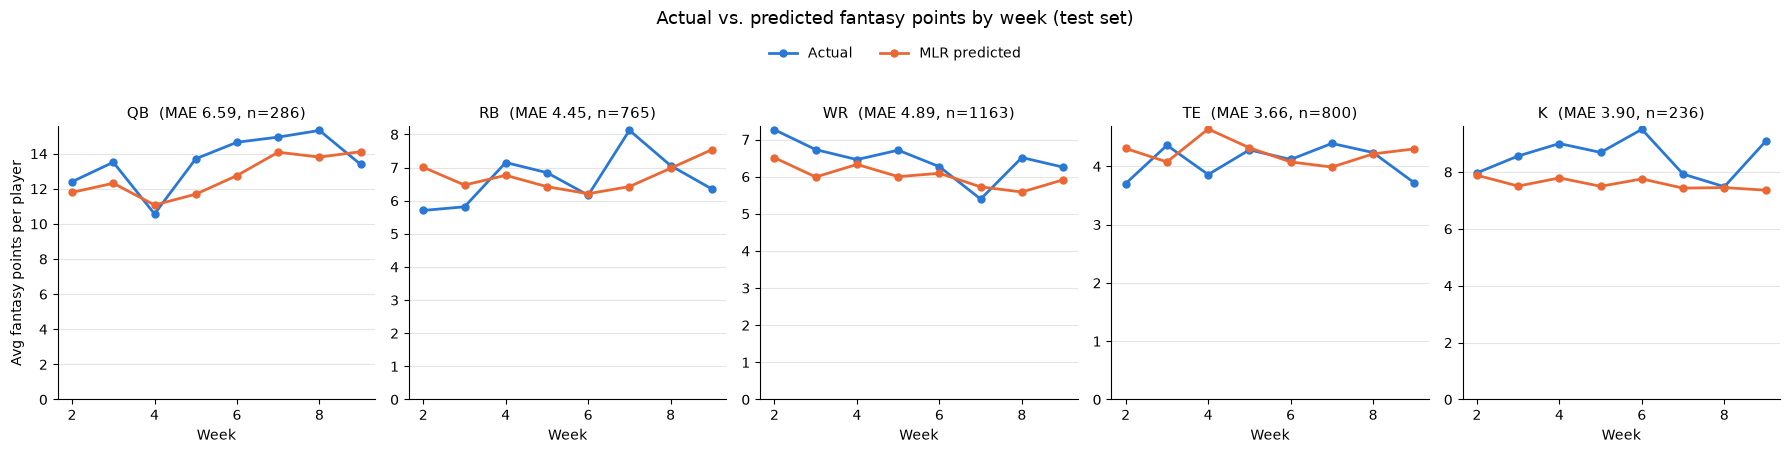

In [ ]:
# Each row's target is NEXT week's points, so shift to the week the points were scored
predictions["target_week"] = X_test["week"] + 1

positions = ["QB", "RB", "WR", "TE", "K"]
ACTUAL_COLOR, PRED_COLOR = "#2a78d6", "#eb6834"

weekly = (
    predictions.groupby(["position", "target_week"])[["actual", "MLR"]]
    .mean()
    .reset_index()
)

fig, axes = plt.subplots(1, len(positions), figsize=(18, 4), sharex=True)
for ax, pos in zip(axes, positions):
    d = weekly[weekly["position"] == pos]
    p = predictions[predictions["position"] == pos]
    mae = mean_absolute_error(p["actual"], p["MLR"])

    ax.plot(d["target_week"], d["actual"], color=ACTUAL_COLOR, lw=2, marker="o", ms=5, label="Actual")
    ax.plot(d["target_week"], d["MLR"], color=PRED_COLOR, lw=2, marker="o", ms=5, label="MLR predicted")

    ax.set_title(f"{pos}  (MAE {mae:.2f}, n={len(p)})", fontsize=11)
    ax.set_xlabel("Week")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", color="#e5e5e5", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Avg fantasy points per player")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.06))
fig.suptitle("Actual vs. predicted fantasy points by week (test set)", y=1.12, fontsize=13)
plt.tight_layout()
#plt.savefig("../figures/MLR_plot.png")
plt.show()